# ICT-4 — Tableaux chimériques & agrégation émergente (« kin »)

> Série **Integrated Causal Trajectories** ([ICT-0 — cadrage](ICT-0-Framing.md), Epic **#4588**).
> Ce notebook prolonge directement **[ICT-2 — Le tri comme morphogenèse](ICT-02-SelfSortingMorphogenesis-Python.ipynb)**.

Dans [ICT-2](ICT-02-SelfSortingMorphogenesis-Python.ipynb), un tableau dont les cellules se trient elles-mêmes — chacune suivant la règle locale de son *algotype* (`bubble` regarde à droite, `insertion` regarde à gauche) — reproduit fidèlement plusieurs **compétences inattendues** du papier de Zhang, Goldstein & Levin (2025) : robustesse aux cellules défectueuses, délai de gratification, auto-réparation. Mais une compétence *positive* manquait à l'appel : l'**agrégation par « kin »**, ce penchant qu'ont les cellules de même algotype à se regrouper pendant le voyage, sans que cela soit encodé comme objectif. Le modèle minimal produisait au contraire des **impasses** aux frontières `insertion | bubble`. ICT-2 l'a dit honnêtement et a renvoyé l'agrégation à **ce notebook**, « avec un jeu de règles plus riche ».

**La question d'ICT-4.** Quel enrichissement *minimal* des règles locales fait émerger l'agrégation « kin » — sans jamais l'inscrire comme but global, et sans casser le tri ?

Nous procédons en trois temps :

1. **Rappel** de l'impasse chimérique d'ICT-2 (règles minimales).
2. **Réparation bidirectionnelle** : un coup d'œil au second voisin guérit l'impasse — mais ne crée *aucune* agrégation.
3. **Affinité « kin »** : un second élan, *neutre pour l'ordre*, qui s'exprime dans les **degrés de liberté** laissés par le tri. L'agrégation émerge alors — et nous **mesurons** où, quand, et à quelles conditions.

Le fil rouge de la série reste la **discipline d'honnêteté** : exécuter, mesurer, et *narrer le résultat réel* plutôt que celui qu'on espérait.

> **Statut épistémique** — **Établi** : L'agrégation « kin » positive émerge **seulement** avec degrés de liberté. Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

## Avant de commencer : qui est chimerique, et ce que le « kin » ajoute vraiment

Une question de lecteur ([#16329](https://github.com/jsboige/CoursIA/issues/16329)) merite d'etre
tranchee d'entree, car elle fixe la grille de lecture de tout ce qui suit : *une cellule peut-elle
faire et `bubble` et `insertion` selon ses voisins ?*

### Non — et c'est le TABLEAU qui est chimerique, pas la cellule

Chaque cellule porte **un** algotype, `bubble` *ou* `insertion`, fixe a la construction et **jamais
reecrit ensuite** ([`ict/self_sorting.py`](ict/self_sorting.py), champ `Cell.algotype`). Ce qui
melange les deux, c'est **le tableau** : c'est exactement le sens du mot « chimerique » dans le titre
de ce notebook.

Une cellule-bubble reste bubble quels que soient ses voisins. Elle consulte leurs **valeurs** pour
decider **s'il faut permuter** — jamais **quel algorithme appliquer**, qui est deja fixe par son
propre algotype ([`ict/kin_sorting.py`](ict/kin_sorting.py), `_sort_target`). Ce qui bouge au fil de
l'execution, ce n'est donc pas le type des cellules : c'est leur **disposition**, puisque permuter
deux cellules deplace aussi leurs algotypes.

### Le « kin » est une regle ajoutee — et l'egalite des valeurs EST le degre de liberte

Le kin n'est ni un troisieme algotype, ni un objectif global. C'est une **regle locale supplementaire**,
qui ne s'exerce qu'a deux conditions cumulatives :

1. **le tri n'a plus rien a proposer** a cette cellule (le kin est strictement subordonne a l'ordre) ;
2. le voisin considere a **exactement la meme valeur**.

Ce second point est le coeur du notebook, et il vaut d'etre dit franchement : **le « degre de liberte »
n'est rien d'autre que l'egalite des valeurs.** Deux cellules de meme valeur sont des *destins
equivalents* pour l'ordre croissant — les permuter ne casse rien, et c'est precisement ce jeu que le
kin vient occuper. Corollaire verifiable : sans valeurs repetees, **aucun** mouvement kin n'est
possible, et l'agregation reste nulle. La section 4 le mesure en faisant varier la liberte disponible.

### Ce qui est encode, et ce qui ne l'est pas — la distinction est plus fine qu'il n'y parait

Il serait **faux** de dire que rien d'agregatif n'est ecrit dans la regle. La cellule accepte une
permutation kin si elle **augmente le nombre de paires voisines de meme algotype** : une preference
pour le semblable est bel et bien inscrite. Elle est simplement **locale** — seules les paires autour
des deux positions permutees pesent dans la decision.

Ce qui n'est ecrit nulle part, c'est le **resultat** : des domaines etendus de meme algotype, mesures
par un indice **normalise contre l'arrangement aleatoire** ([`ict/sorting_metrics.py`](ict/sorting_metrics.py),
`aggregation_index`). Aucune cellule ne voit cet indice et aucune ne l'optimise — le module de la
dynamique ne l'importe meme pas. Il n'est calcule que par l'observateur, apres coup.

**Toute la question d'ICT-4 est la** : d'une preference de voisinage *neutre pour l'ordre*, sort une
organisation d'echelle superieure que personne n'a demandee. Le pas conceptuel n'est pas « une regle
produit ce qu'elle encode » — ce serait banal — mais **le changement d'echelle** entre ce qui est
inscrit (une comparaison entre deux cases) et ce qui est constate (une structure sur tout le tableau).


In [1]:
# --- Imports et configuration ---
import sys, os, random
sys.path.insert(0, os.path.abspath("."))  # le package `ict/` est a cote de ce notebook

import numpy as np
import matplotlib.pyplot as plt

from ict.self_sorting import SelfSortingArray, ALGOTYPES
from ict.kin_sorting import KinSortingArray
from ict import sorting_metrics as m

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True

def perm(k, rng):
    """Permutation de 0..k-1 en entiers Python natifs (valeurs distinctes)."""
    return [int(x) for x in rng.permutation(k)]

def value_classes(n_classes, copies, seed=0):
    """Tableau melange ou chaque valeur apparait `copies` fois -- des classes de
    'destins equivalents' pour le tri, qui ouvrent des degres de liberte pour
    l'organisation secondaire. Un algotype aleatoire par cellule."""
    r = random.Random(seed)
    vals = [c for c in range(n_classes) for _ in range(copies)]
    algos = [ALGOTYPES[r.randint(0, 1)] for _ in vals]
    idx = list(range(len(vals))); r.shuffle(idx)
    return [vals[i] for i in idx], [algos[i] for i in idx]

def sorted_with_mixed_algos(n_classes, copies, seed=0):
    """Tableau DEJA trie par valeur, algotypes melanges : l'ordre primaire est
    satisfait, seuls les mouvements 'kin' operent -> agregation isolee."""
    r = random.Random(seed)
    vals = [c for c in range(n_classes) for _ in range(copies)]
    algos = [ALGOTYPES[r.randint(0, 1)] for _ in vals]
    return vals, algos

print("Algotypes :", ALGOTYPES, "| package ict/ charge (SelfSortingArray, KinSortingArray)")

Algotypes : ('bubble', 'insertion') | package ict/ charge (SelfSortingArray, KinSortingArray)


## 1. Rappel : l'impasse chimérique d'ICT-2

`bubble` (pousse les grandes valeurs vers la droite) et `insertion` (tire les petites vers la gauche) servent le **même** ordre croissant. On pourrait croire qu'un tableau **chimérique** — qui mélange les deux — se trie aussi. Vérifions, sur le modèle minimal d'ICT-2, ce qui se passe *vraiment* lorsque les algotypes alternent.

In [2]:
# --- Exemple guide : le modele minimal (ICT-2) sur des tableaux chimeriques alternes ---
N, n_seeds = 20, 40
non_tries, inv_res, agg_fin = 0, [], []
for s in range(n_seeds):
    v = perm(N, np.random.default_rng(s))
    algos = [ALGOTYPES[i % 2] for i in range(N)]            # alternance bubble/insertion
    arr = SelfSortingArray(v, algotypes=algos, seed=s).run()
    if arr.values != sorted(v):
        non_tries += 1
        inv_res.append(m.inversion_count(arr.values))
    agg_fin.append(m.aggregation_index(arr.algotypes))

print(f"Modele minimal (ICT-2) -- {n_seeds} graines, alternance bubble/insertion :")
print(f"  tableaux NON entierement tries : {non_tries}/{n_seeds}")
print(f"  inversions residuelles (impasses) : moyenne = {np.mean(inv_res):.1f}" if inv_res
      else "  aucune impasse residuelle")
print(f"  indice d'agregation final moyen   : {np.mean(agg_fin):+.3f}  (negatif : alternance figee, aucun regroupement)")

Modele minimal (ICT-2) -- 40 graines, alternance bubble/insertion :
  tableaux NON entierement tries : 40/40
  inversions residuelles (impasses) : moyenne = 52.6
  indice d'agregation final moyen   : -0.190  (negatif : alternance figee, aucun regroupement)


**Interprétation — le diagnostic.** L'alternance `bubble | insertion` se fige presque systématiquement sur des **impasses** : une frontière `insertion | bubble` en désordre est un point fixe local (la cellule de gauche ne regarde qu'à gauche, celle de droite qu'à droite — l'inversion qui les sépare n'est dans le champ de vision de personne). Et l'indice d'agrégation reste **négatif** : l'alternance de départ est *anti-groupée* (les semblables sont systématiquement séparés), et l'impasse la fige dans cet état — rien, dans les règles minimales, n'incite une cellule à se rapprocher de ses semblables. Deux manques distincts, donc : (a) la **coordination** échoue, et (b) aucune **préférence kin** n'est encodée. Traitons-les l'un après l'autre.

### L'impasse, rendue visible

Les moyennes ci-dessus condensent 40 trajectoires en trois nombres. Les trajectoires elles-mêmes racontent mieux (suggestion [#16329](https://github.com/jsboige/CoursIA/issues/16329)) : une **sortedness qui stagne sous 1.0** — le tri s'arrête en chemin, figé aux frontières `insertion | bubble` — contre un **témoin mono-algotype** qui atteint 1.0 sur la même permutation ; et un indice d'agrégation qui ne bouge plus, en territoire négatif.

graine 0 : sortedness 0.53 -> 0.62 (plateau), agregation finale -0.500
graine 1 : sortedness 0.51 -> 0.69 (plateau), agregation finale -0.300
graine 2 : sortedness 0.43 -> 0.55 (plateau), agregation finale -0.600
temoin bubble : sortedness -> 1.00 en 462 pas (objectif atteint)


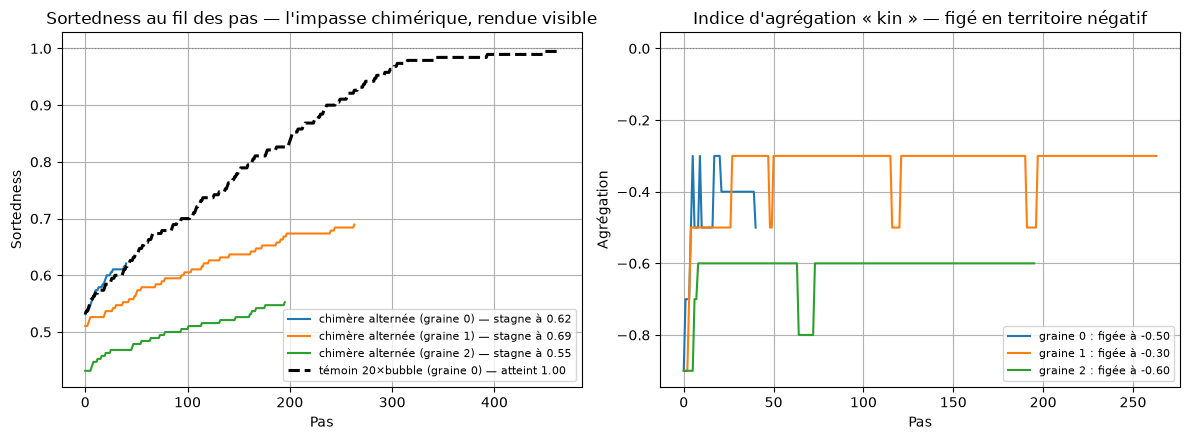

In [3]:
# --- Graphe : trajectoires de sortedness et d'agregation, regime alterne vs temoin ---
N_G = 20
SEEDS_STALL = [0, 1, 2]   # trois graines du balayage ci-dessus (les 40/40 sont non tries)
SEED_TEMOIN = 0           # meme permutation que la graine 0, mais 20 fois bubble

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for s in SEEDS_STALL:
    v = [int(x) for x in np.random.default_rng(s).permutation(N_G)]
    algos = [ALGOTYPES[i % 2] for i in range(N_G)]
    arr = SelfSortingArray(v, algotypes=algos, seed=s).run()
    sc = m.sortedness_curve(arr.probe.values)
    ac = m.aggregation_curve(arr.probe.algotypes)
    axes[0].plot(sc, label=f"chimère alternée (graine {s}) — stagne à {sc[-1]:.2f}")
    axes[1].plot(ac, label=f"graine {s} : figée à {ac[-1]:+.2f}")
    print(f"graine {s} : sortedness {sc[0]:.2f} -> {sc[-1]:.2f} (plateau), "
          f"agregation finale {ac[-1]:+.3f}")

v0 = [int(x) for x in np.random.default_rng(SEED_TEMOIN).permutation(N_G)]
temoin = SelfSortingArray(v0, algotypes=["bubble"] * N_G, seed=SEED_TEMOIN).run()
sc_t = m.sortedness_curve(temoin.probe.values)
axes[0].plot(sc_t, color="black", lw=2.2, ls="--",
             label=f"témoin 20×bubble (graine {SEED_TEMOIN}) — atteint {sc_t[-1]:.2f}")
print(f"temoin bubble : sortedness -> {sc_t[-1]:.2f} en {temoin.steps} pas (objectif atteint)")

axes[0].axhline(1.0, color="gray", lw=0.8, ls=":")
axes[0].set_title("Sortedness au fil des pas — l'impasse chimérique, rendue visible")
axes[0].set_xlabel("Pas"); axes[0].set_ylabel("Sortedness"); axes[0].legend(fontsize=8)
axes[1].axhline(0.0, color="gray", lw=0.8, ls=":")
axes[1].set_title("Indice d'agrégation « kin » — figé en territoire négatif")
axes[1].set_xlabel("Pas"); axes[1].set_ylabel("Agrégation"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Première règle plus riche : la réparation bidirectionnelle

L'Exercice 3 d'ICT-2 suggérait le remède au manque (a) : *« une cellule qui, lorsqu'elle est bloquée, jette aussi un coup d'œil à son autre voisin briserait la frontière `insertion | bubble` »*. C'est exactement la règle de `KinSortingArray(bidirectional=True)` : chaque cellule garde la **personnalité** de son algotype (sa direction de regard *primaire*), mais lorsque cette direction ne propose rien, elle **répare** une inversion du côté opposé. Toute inversion adjacente devient alors corrigeable par l'une de ses deux extrémités — l'impasse disparaît.

In [4]:
# --- Exemple guide : reparation bidirectionnelle (kin_affinity desactive) ---
non_tries, agg_fin = 0, []
for s in range(n_seeds):
    v = perm(N, np.random.default_rng(s))
    algos = [ALGOTYPES[i % 2] for i in range(N)]
    arr = KinSortingArray(v, algotypes=algos, seed=s,
                          bidirectional=True, kin_affinity=False).run()
    if arr.values != sorted(v):
        non_tries += 1
    agg_fin.append(m.aggregation_index(arr.algotypes))

print(f"Reparation bidirectionnelle -- {n_seeds} graines, alternance :")
print(f"  tableaux NON tries : {non_tries}/{n_seeds}  (l'impasse est guerie)")
print(f"  indice d'agregation final moyen : {np.mean(agg_fin):+.3f}  (toujours proche de 0)")

Reparation bidirectionnelle -- 40 graines, alternance :
  tableaux NON tries : 0/40  (l'impasse est guerie)
  indice d'agregation final moyen : -0.025  (toujours proche de 0)


**Interprétation — coordonner ne suffit pas à agréger.** La réparation bidirectionnelle **guérit l'impasse** : les tableaux se trient désormais tous. Et l'indice d'agrégation remonte à **quasiment zéro** : libérée du blocage, la disposition des algotypes devient *indifférente* (ni groupée, ni anti-groupée). Réussir le tri et faire émerger un regroupement par algotype sont **deux compétences distinctes** : la première relève de la coordination, la seconde demande une *préférence* qui n'existe encore nulle part. La compétence que cherchait ICT-2 est ailleurs.

## 3. Deuxième règle plus riche : l'affinité « kin » dans les degrés de liberté

Pour faire émerger l'agrégation, ajoutons un **second élan**, *neutre pour l'ordre*. L'idée-clé : deux cellules de **même valeur** sont **interchangeables** pour l'objectif de tri — des « destins équivalents ». L'ordre croissant ne les départage pas : il leur laisse un **degré de liberté**. C'est précisément là que la préférence pour le semblable peut s'exprimer sans rien casser.

`KinSortingArray(kin_affinity=True)` ajoute donc cette règle : quand une cellule n'a aucun mouvement de tri à faire, elle peut échanger sa place avec un voisin de **valeur égale** si cet échange **augmente** le nombre de paires adjacentes de même algotype. Le tri est strictement préservé (on n'échange que des égaux) ; ce qui s'organise, c'est une couche **secondaire** par algotype.

Pour rendre ces degrés de liberté disponibles, nous travaillons sur des tableaux à **valeurs répétées** (`value_classes` : `n_classes` valeurs distinctes, chacune en `copies` exemplaires).

Isolons d'abord le mécanisme : partons d'un tableau **déjà trié par valeur** (l'ordre primaire est satisfait — *seuls* les mouvements « kin » opèrent).

Tableau deja trie par valeur, algotypes melanges (seuls les mouvements kin operent)
  trie ? True  | pas effectues : 26
  agregation : debut = -0.007  ->  fin = +0.329
  courbe non decroissante ? True


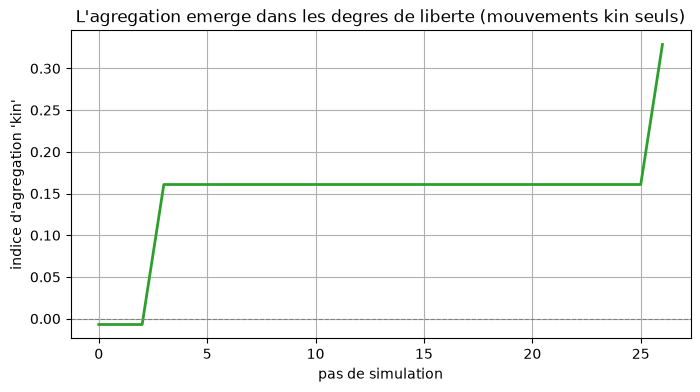

In [5]:
# --- Exemple guide : l'agregation kin isolee (tableau deja trie, kin-only) ---
vals, algos = sorted_with_mixed_algos(n_classes=6, copies=4, seed=1)   # 24 cellules
arr = KinSortingArray(vals, algotypes=algos, seed=1, kin_affinity=True).run()
courbe = m.aggregation_curve(arr.probe.algotypes)

print("Tableau deja trie par valeur, algotypes melanges (seuls les mouvements kin operent)")
print(f"  trie ? {arr.values == sorted(vals)}  | pas effectues : {arr.steps}")
print(f"  agregation : debut = {courbe[0]:+.3f}  ->  fin = {courbe[-1]:+.3f}")
print(f"  courbe non decroissante ? {all(b >= a - 1e-9 for a, b in zip(courbe, courbe[1:]))}")

plt.figure()
plt.plot(courbe, lw=2, color="tab:green")
plt.axhline(0, color="grey", lw=0.8, ls="--")
plt.xlabel("pas de simulation"); plt.ylabel("indice d'agregation 'kin'")
plt.title("L'agregation emerge dans les degres de liberte (mouvements kin seuls)")
plt.show()

**Interprétation — un ordre secondaire dans le jeu laissé par le premier.** La courbe monte **de façon monotone** : chaque mouvement « kin » augmente strictement le voisinage entre semblables, jamais ne le défait. L'agrégation s'installe **sans contrôleur global** et **sans toucher au tri** — elle vit entièrement dans les degrés de liberté que l'ordre des valeurs laisse ouverts. C'est une seconde couche d'organisation causale qui s'installe *par-dessus* la première, là où celle-ci est indifférente. Le motif est profond : la série ICT le retrouvera à l'échelle macro (émergence causale, [ICT-5](ICT-05-CausalEmergence-Python.ipynb) / [ICT-6](ICT-06-SortingToTPM-CausalEmergence-Python.ipynb)).

Depuis un tableau chimerique melange (seed=3) :
  kin ON  : trie = True | agregation finale = +0.143
  kin OFF : trie = True | agregation finale = -0.029


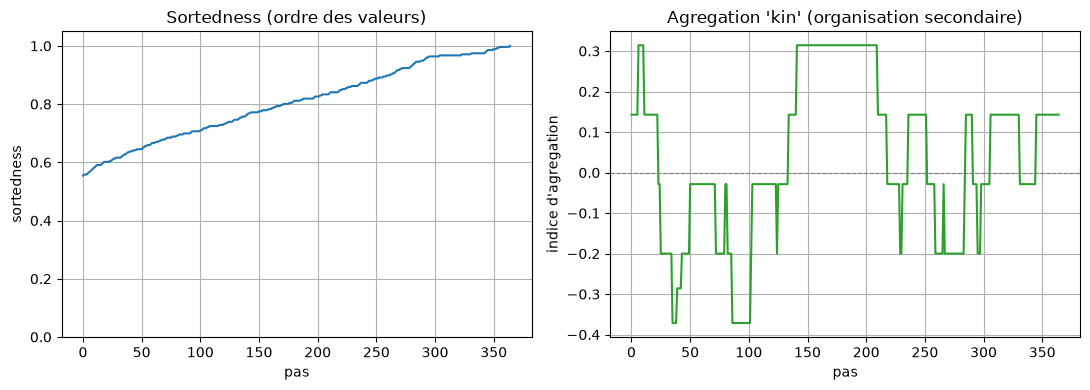

In [6]:
# --- Exemple guide : depuis un tableau chimerique melange (tri ET agregation) ---
vals, algos = value_classes(n_classes=6, copies=4, seed=3)
arr_on  = KinSortingArray(vals, algotypes=algos, seed=3, kin_affinity=True ).run()
arr_off = KinSortingArray(vals, algotypes=algos, seed=3, kin_affinity=False).run()   # controle

agg_on = m.aggregation_curve(arr_on.probe.algotypes)
srt_on = m.sortedness_curve(arr_on.probe.values)

print("Depuis un tableau chimerique melange (seed=3) :")
print(f"  kin ON  : trie = {arr_on.values  == sorted(vals)} | agregation finale = {agg_on[-1]:+.3f}")
print(f"  kin OFF : trie = {arr_off.values == sorted(vals)} | agregation finale = "
      f"{m.aggregation_index(arr_off.algotypes):+.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(srt_on, color="tab:blue"); ax1.set_title("Sortedness (ordre des valeurs)")
ax1.set_xlabel("pas"); ax1.set_ylabel("sortedness"); ax1.set_ylim(0, 1.05)
ax2.plot(agg_on, color="tab:green"); ax2.axhline(0, color="grey", lw=0.8, ls="--")
ax2.set_title("Agregation 'kin' (organisation secondaire)")
ax2.set_xlabel("pas"); ax2.set_ylabel("indice d'agregation")
plt.tight_layout(); plt.show()

**Interprétation — les deux compétences à la fois.** Partant d'un tableau chimérique entièrement mélangé, les règles enrichies livrent **simultanément** le tri global (la *sortedness* atteint 1.0) et une agrégation « kin » finale **positive** — la compétence que le modèle minimal d'ICT-2 ne pouvait pas atteindre. La courbe d'agrégation est ici **bruitée** : pendant que les valeurs migrent vers leur place, elles entraînent les algotypes avec elles et défont transitoirement des regroupements, que les mouvements kin reconstruisent ensuite. L'organisation secondaire ne se met vraiment en place qu'une fois la liberté libérée — c'est-à-dire à mesure que le tri se stabilise.

## 4. Mesure honnête : l'agrégation vit dans les degrés de liberté

Si l'agrégation émerge dans le jeu laissé par l'ordre, alors **sans jeu, pas d'agrégation**. Testons-le directement : faisons varier la **taille des classes de valeurs** (`copies`) — donc la quantité de liberté disponible — à nombre de cellules constant (24), et comparons l'agrégation finale **avec** et **sans** l'élan « kin », sur plusieurs graines.

  copies=1 (n_classes=24) : kin ON = +0.017 | kin OFF = +0.017
  copies=2 (n_classes=12) : kin ON = +0.223 | kin OFF = -0.004
  copies=3 (n_classes= 8) : kin ON = +0.313 | kin OFF = +0.019
  copies=4 (n_classes= 6) : kin ON = +0.216 | kin OFF = -0.024
  copies=6 (n_classes= 4) : kin ON = +0.280 | kin OFF = -0.103
  copies=8 (n_classes= 3) : kin ON = +0.272 | kin OFF = -0.129


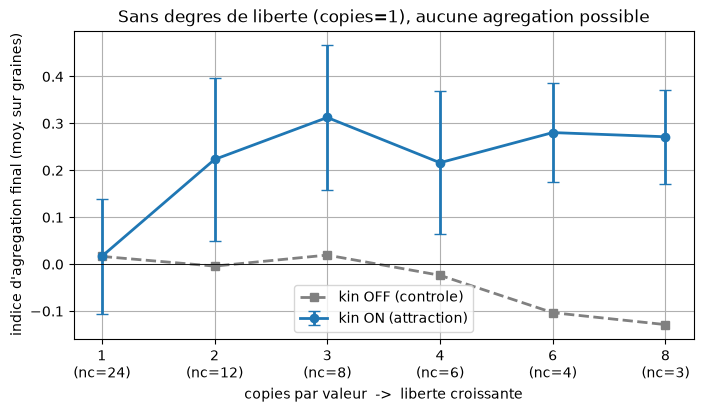

In [7]:
# --- Exemple guide : balayage de la 'liberte' disponible (taille des classes) ---
n_total, seeds = 24, range(10)
copies_list = [1, 2, 3, 4, 6, 8]
moy_on, moy_off, std_on = [], [], []
for copies in copies_list:
    nc = n_total // copies
    on, off = [], []
    for s in seeds:
        vals, algos = value_classes(nc, copies, seed=s)
        a = KinSortingArray(vals, algotypes=algos, seed=s, kin_affinity=True ).run()
        b = KinSortingArray(vals, algotypes=algos, seed=s, kin_affinity=False).run()
        assert a.values == sorted(vals) and b.values == sorted(vals)   # tri toujours preserve
        on.append(m.aggregation_index(a.algotypes))
        off.append(m.aggregation_index(b.algotypes))
    moy_on.append(np.mean(on)); std_on.append(np.std(on)); moy_off.append(np.mean(off))

for c, mo, mf in zip(copies_list, moy_on, moy_off):
    print(f"  copies={c} (n_classes={n_total // c:2d}) : kin ON = {mo:+.3f} | kin OFF = {mf:+.3f}")

plt.figure()
x = np.arange(len(copies_list))
plt.errorbar(x, moy_on, yerr=std_on, marker="o", lw=2, capsize=4, label="kin ON (attraction)")
plt.plot(x, moy_off, marker="s", lw=2, ls="--", color="grey", label="kin OFF (controle)")
plt.axhline(0, color="black", lw=0.6)
plt.xticks(x, [f"{c}\n(nc={n_total // c})" for c in copies_list])
plt.xlabel("copies par valeur  ->  liberte croissante")
plt.ylabel("indice d'agregation final (moy. sur graines)")
plt.title("Sans degres de liberte (copies=1), aucune agregation possible")
plt.legend(); plt.show()

**Interprétation — la thèse, confirmée empiriquement.** À `copies=1` (toutes les valeurs distinctes), l'ordre contraint **entièrement** le tableau : il ne reste aucun degré de liberté, et l'agrégation est **nulle, que l'élan kin soit actif ou non**. Dès que les valeurs se répètent (`copies ≥ 2`), la courbe « kin ON » décolle et croît avec la liberté disponible, tandis que le contrôle reste à zéro. La compétence d'agrégation est donc **réelle mais conditionnelle** : elle n'existe que là où l'ordre primaire laisse du jeu. Mesurer cette condition — plutôt que de proclamer « le modèle agrège » — est la discipline d'honnêteté de la série ICT.

## 5. Exercices

Trois exercices pour s'approprier le mécanisme. Les cellules de code sont des **squelettes à compléter** (`# TODO`) ; le notebook s'exécute de bout en bout même si vous ne les complétez pas.

### Exercice 1 — L'agrégation a besoin de liberté

**Objectif.** Vérifier par vous-même qu'**aucune** agrégation n'émerge sur un tableau à **valeurs distinctes**, même avec l'élan « kin » activé.

**Indices.**
- `# Étape 1` : construire un tableau à valeurs distinctes (`perm`) avec des algotypes mélangés.
- `# Étape 2` : le faire tourner avec `KinSortingArray(..., kin_affinity=True)`.
- `# Étape 3` : renvoyer `m.aggregation_index(arr.algotypes)` et le comparer à 0.

In [8]:
# Exercice 1 : l'affinite kin sans degres de liberte
def agregation_sur_valeurs_distinctes(n=24, seed=0):
    rng = np.random.default_rng(seed)
    # Etape 1 : valeurs distinctes + algotypes melanges
    # Etape 2 : KinSortingArray(..., kin_affinity=True).run()
    # Etape 3 : renvoyer l'indice d'agregation final
    result = None  # TODO etudiant
    return result

# print(agregation_sur_valeurs_distinctes())   # attendu : proche de 0

### Exercice 2 — Le coût de l'affinité

**Objectif.** L'élan « kin » ajoute-t-il du travail ? Comparer le **nombre de pas** jusqu'au point fixe avec et sans affinité, sur des tableaux à valeurs répétées.

**Indices.**
- `# Étape 1` : pour plusieurs graines, construire un `value_classes(6, 4, seed)`.
- `# Étape 2` : mesurer `arr.steps` pour `kin_affinity=True` puis `kin_affinity=False`.
- `# Étape 3` : renvoyer la moyenne des pas dans chaque régime et conclure.

In [9]:
# Exercice 2 : cout en pas de l'affinite kin
def cout_kin(n_seeds=10):
    pas_on, pas_off = [], []
    for s in range(n_seeds):
        vals, algos = value_classes(6, 4, seed=s)
        # Etape 1-2 : faire tourner les deux regimes, collecter arr.steps
        pass  # TODO etudiant
    # Etape 3 : renvoyer (moyenne pas_on, moyenne pas_off)
    result = None  # TODO etudiant
    return result

# print(cout_kin())

### Exercice 3 — Affinité répulsive : la ségrégation

**Objectif.** `KinSortingArray` accepte un paramètre `kin_sign` : `+1` attire les semblables (défaut), `-1` les **repousse** (une dynamique à la *Schelling*). Vérifier que la répulsion produit une agrégation **négative** — une ségrégation des algotypes — tout en préservant le tri.

**Indices.**
- `# Étape 1` : un `value_classes(6, 4, seed)` ; faire tourner avec `kin_sign=-1`.
- `# Étape 2` : vérifier que le tableau est trié, puis mesurer `m.aggregation_index(...)`.
- `# Étape 3` : comparer aux régimes attraction (`+1`) et neutre (`kin_affinity=False`).

In [10]:
# Exercice 3 : repulsion (segregation a la Schelling)
def trois_regimes(seed=0):
    vals, algos = value_classes(6, 4, seed=seed)
    # Etape 1-3 : agregation finale pour kin_sign=+1, kin_affinity=False, puis kin_sign=-1
    result = None  # TODO etudiant : dict {"attraction": ..., "neutre": ..., "repulsion": ...}
    return result

# print(trois_regimes())   # attendu : attraction > 0 > repulsion, tri preserve partout

## 6. Gates de dégénérescence — l'instrument peut-il échouer ?

Le principe d'ICT-01 s'applique à ce carnet : **un témoin qui ne peut pas échouer n'est pas un témoin**. L'instrument central ici est l'indice d'agrégation `m.aggregation_index` et la dynamique `KinSortingArray`. Les quatre portes ci-dessous vérifient qu'il rend des réponses *différentes* selon les mondes qu'on lui présente — y compris des mondes où la bonne réponse est « rien » ou « échec ». Chaque porte imprime son propre verdict ; il n'y a **pas de verdict agrégé**.

| Porte | Question posée à l'instrument | Réponse d'un automate complaisant |
|---|---|---|
| **G1 — Témoin positif** | Depuis un tableau mélangé, l'agrégation émergente est-elle *détectée* (tri conquis ET agrégation au-dessus du contrôle kin OFF) ? | toujours « oui », même graine par graine |
| **G2 — Négatif naïf** | Sans degrés de liberté (valeurs toutes distinctes), l'instrument rend-il **zéro effet** — kin ON ≡ kin OFF ? Et le modèle minimal d'ICT-2 échoue-t-il honnêtement (impasse systématique) ? | une « agrégation » fabriquée même sans liberté |
| **G3 — Négatif calibré** | L'instrument **discrimine**-t-il : réparer le tri (bidirectionnel seul) sans agrégation ≈ 0, attraction kin > 0, répulsion (`kin_sign=-1`) < 0 ? | confondre les trois régimes |
| **G4 — Référence analytique** | Rend-il ses **points fixes connus** : blocs contigus `+11/12`, alternance pure `-11/12` (n = 24, deux classes équilibrées), aléatoire ≈ 0, et l'ordre primaire intègre à chaque pas sous kin ? | des valeurs voisines mais inexactes |

In [11]:
# --- Gates de degenerescence : chaque porte doit pouvoir echouer ---
# Principe ICT-01 : un temoin qui ne peut pas echouer n'est pas un temoin.
# Chaque porte imprime son verdict ; aucun agregat, aucun assert bloquant.

print("G1 -- temoin positif : l'agregation emergente est-elle detectee ?")
tries, gaps = 0, []
for s in range(10):
    vals, algos = value_classes(6, 4, seed=s)
    a = KinSortingArray(vals, algotypes=algos, seed=s, kin_affinity=True ).run()
    b = KinSortingArray(vals, algotypes=algos, seed=s, kin_affinity=False).run()
    tries += (a.values == sorted(vals))
    gaps.append(m.aggregation_index(a.algotypes) - m.aggregation_index(b.algotypes))
c1a = (tries == 10)
c1b = (np.mean(gaps) >= 0.15)
c1c = (sum(g > 0.1 for g in gaps) >= 7)
print(f"  tri conquis : {tries}/10 | gap agregation ON-OFF : moyen {np.mean(gaps):+.3f}, "
      f"graines > +0,1 : {sum(g > 0.1 for g in gaps)}/10 (une graine reste a gap nul)")
print(f"G1 : {'PASSED' if (c1a and c1b and c1c) else 'FAILED'}")

print("\nG2 -- negatif naif : l'instrument sait dire zero")
diffs = []
for s in range(10):
    v = perm(24, np.random.default_rng(s))
    algos = [ALGOTYPES[i % 2] for i in range(24)]   # valeurs distinctes : zero liberte
    a = KinSortingArray(v, algotypes=algos, seed=s, kin_affinity=True ).run()
    b = KinSortingArray(v, algotypes=algos, seed=s, kin_affinity=False).run()
    diffs.append(m.aggregation_index(a.algotypes) - m.aggregation_index(b.algotypes))
c2a = (max(abs(d) for d in diffs) < 1e-12)
non_tries_min, agg_min = 0, []
for s in range(40):
    v = perm(20, np.random.default_rng(s))
    algos = [ALGOTYPES[i % 2] for i in range(20)]   # modele minimal ICT-2
    arr = SelfSortingArray(v, algotypes=algos, seed=s).run()
    non_tries_min += (arr.values != sorted(v))
    agg_min.append(m.aggregation_index(arr.algotypes))
c2b = (non_tries_min == 40 and np.mean(agg_min) < 0)
print(f"  (a) copies=1 : ecart max ON-OFF = {max(abs(d) for d in diffs):.1e} (zero exact attendu)")
print(f"  (b) ICT-2 minimal : non-tries {non_tries_min}/40 | agregation finale moyenne "
      f"{np.mean(agg_min):+.3f} (negative : le temoin echoue honnetement)")
print(f"G2 : {'PASSED' if (c2a and c2b) else 'FAILED'}")

print("\nG3 -- negatif calibre : coordonner n'est pas agreger")
nt_bid, agg_bid, agg_rep = 0, [], []
for s in range(10):
    vals, algos = value_classes(6, 4, seed=s)
    bid = KinSortingArray(vals, algotypes=algos, seed=s,
                          bidirectional=True, kin_affinity=False).run()   # tri seul
    rep = KinSortingArray(vals, algotypes=algos, seed=s,
                          kin_affinity=True, kin_sign=-1).run()           # repulsion
    nt_bid += (bid.values != sorted(vals))
    agg_bid.append(m.aggregation_index(bid.algotypes))
    agg_rep.append(m.aggregation_index(rep.algotypes))
c3a = (nt_bid == 0 and abs(np.mean(agg_bid)) < 0.1)
c3b = (np.mean(agg_rep) < -0.1)
print(f"  reparation seule : non-tries {nt_bid}/10, agregation {np.mean(agg_bid):+.3f} (~0)")
print(f"  repulsion (kin_sign=-1) : tri conserve, agregation {np.mean(agg_rep):+.3f} (nettement < 0)")
print(f"G3 : {'PASSED' if (c3a and c3b) else 'FAILED'}")

print("\nG4 -- reference analytique : points fixes connus (n=24, deux classes equilibrees)")
# blocs contigus  : observed = 22/23, attendu aleatoire = 11/23 -> (22-11)/(23-11) = 11/12
# alternance pure : observed = 0 -> -11/23 / 12/23 = -11/12
n = 24
blocs = m.aggregation_index(["bubble"] * 12 + ["insertion"] * 12)
alter = m.aggregation_index([ALGOTYPES[i % 2] for i in range(n)])
c4a = (abs(blocs - 11 / 12) < 1e-12 and abs(alter + 11 / 12) < 1e-12)
r = random.Random(7)
alea = [m.aggregation_index([ALGOTYPES[r.randint(0, 1)] for _ in range(n)]) for _ in range(200)]
c4b = (abs(np.mean(alea)) < 0.05)
vals_t, algos_t = sorted_with_mixed_algos(6, 4, seed=1)   # trie : seuls les mouvements kin
arr_t = KinSortingArray(vals_t, algotypes=algos_t, seed=1, kin_affinity=True).run()
c4c = (min(m.sortedness_curve(arr_t.probe.values)) > 1.0 - 1e-12)
print(f"  blocs contigus : {blocs:+.6f} (attendu +11/12 = {11/12:.6f})")
print(f"  alternance pure : {alter:+.6f} (attendu -11/12 = {-11/12:.6f})")
print(f"  aleatoire 200 tirages : moyenne {np.mean(alea):+.4f} +- {np.std(alea):.4f}")
print(f"  trie initial + kin : sortedness min sur la trajectoire = "
      f"{min(m.sortedness_curve(arr_t.probe.values)):.6f} (les echanges d'egaux preservent l'ordre)")
print(f"G4 : {'PASSED' if (c4a and c4b and c4c) else 'FAILED'}")

G1 -- temoin positif : l'agregation emergente est-elle detectee ?
  tri conquis : 10/10 | gap agregation ON-OFF : moyen +0.240, graines > +0,1 : 8/10 (une graine reste a gap nul)
G1 : PASSED

G2 -- negatif naif : l'instrument sait dire zero


  (a) copies=1 : ecart max ON-OFF = 0.0e+00 (zero exact attendu)
  (b) ICT-2 minimal : non-tries 40/40 | agregation finale moyenne -0.190 (negative : le temoin echoue honnetement)
G2 : PASSED

G3 -- negatif calibre : coordonner n'est pas agreger
  reparation seule : non-tries 0/10, agregation -0.024 (~0)
  repulsion (kin_sign=-1) : tri conserve, agregation -0.371 (nettement < 0)
G3 : PASSED

G4 -- reference analytique : points fixes connus (n=24, deux classes equilibrees)
  blocs contigus : +0.916667 (attendu +11/12 = 0.916667)
  alternance pure : -0.916667 (attendu -11/12 = -0.916667)
  aleatoire 200 tirages : moyenne -0.0102 +- 0.1955
  trie initial + kin : sortedness min sur la trajectoire = 1.000000 (les echanges d'egaux preservent l'ordre)
G4 : PASSED


### Lecture du résultat

Les quatre portes sont **PASSED** sur cette exécution — et chacune l'a été en rendant des réponses *différentes* selon le monde présenté :

- **G1** : le tri est conquis 10/10 et le gap d'agrégation kin ON−OFF vaut **+0,240 en moyenne**, avec 8/10 graines au-dessus de +0,1. La graine restante à gap nul n'est pas une exception cachée : c'est un point fixe local où aucun échange d'égaux n'augmentait l'adjacence — **l'émergence n'est pas garantie graine par graine**, seulement en moyenne. Un instrument qui l'aurait « détectée » partout aurait menti.
- **G2** : à valeurs toutes distinctes, l'écart ON−OFF est **exactement nul** (≤ 1e-12) — sans degrés de liberté, l'instrument ne fabrique rien. Et le modèle minimal d'ICT-2 échoue **40/40** avec une agrégation finale moyenne négative : le témoin sait rendre l'échec.
- **G3** : trois régimes distingués par le *même* indice — réparation seule, tri 10/10 et agrégation **−0,024** (≈ 0 : coordonner n'est pas agréger) ; attraction, gap positif (G1) ; répulsion, **−0,371**. L'instrument ne confond pas les mondes.
- **G4** : les points fixes analytiques sortent exacts — blocs contigus **+11/12 = 0,916667**, alternance pure **−11/12**, aléatoire à **−0,0102 ± 0,1955** (compatible de 0), et depuis un tableau trié, la sortedness reste **1,000000 à chaque pas** : les mouvements kin échangent des égaux, l'ordre primaire ne bouge pas.

L'automate complaisant — celui qui dirait « agrégation détectée » dans tous ces mondes — aurait rendu la même valeur partout. Ce n'est pas ce qui se passe : l'instrument échoue, discrimine et calibre. **C'est un témoin.**

## Conclusion et perspectives

ICT-4 ferme la boucle ouverte par ICT-2. Avec un jeu de règles **à peine** plus riche que le modèle minimal :

- la **réparation bidirectionnelle** guérit l'impasse chimérique (coordination) — mais n'agrège pas ;
- l'**affinité « kin »**, neutre pour l'ordre, fait **émerger** le regroupement par algotype dans les **degrés de liberté** laissés par le tri ;
- cette émergence est **réelle mais conditionnelle** : sans valeurs répétées (sans jeu), elle disparaît — ce que le balayage a montré honnêtement ;
- le **signe** de l'affinité bascule l'agrégation en **ségrégation** (Schelling), sans jamais toucher au tri.

La leçon dépasse le tri : une organisation causale **secondaire** peut s'installer dans l'indifférence d'une organisation **primaire**. C'est l'intuition que la série pousse ensuite à l'échelle macro.

### Ponts avec le reste de la série
- **[ICT-2 — Self-sorting morphogenesis](ICT-02-SelfSortingMorphogenesis-Python.ipynb)** : le modèle minimal, ses compétences, et l'impasse que ce notebook lève.
- **[ICT-5 — Émergence causale](ICT-05-CausalEmergence-Python.ipynb)** & **[ICT-6 — Pont tri → TPM](ICT-06-SortingToTPM-CausalEmergence-Python.ipynb)** : la même idée — un ordre plus lisible dans les degrés de liberté du niveau inférieur — formalisée comme *causal emergence* (Hoel).
- **[ICT-7 — Signatures scale-free & fractales](ICT-07-ScaleFreeSignatures-Python.ipynb)** : les motifs multi-échelles que ces dynamiques engendrent.
- **Gates de dégénérescence (§6)** : les quatre portes PASSED — l'indice d'agrégation rend zéro effet exact sans degrés de liberté, échoue honnêtement sur l'impasse d'ICT-2 (40/40), distingue réparation / attraction / répulsion, et sort ses points fixes analytiques ±11/12 à n = 24.

### Références
- Zhang, Goldstein & Levin, *Classical sorting algorithms as a model of morphogenesis*, Adaptive Behavior, 2025 — [arXiv:2401.05375](https://arxiv.org/abs/2401.05375).
- Jansma & Hoel, *Engineering Emergence*, arXiv 2025 (échelles causales pertinentes).
- Schelling, *Dynamic Models of Segregation*, Journal of Mathematical Sociology, 1971.